# AI Business Data Chatbot
## Part 1: Load, Clean, Explore and Analyse the data
Each cell does ONE small job. Run them from top to bottom.

## Step 1: Get the dataset

### 1.1 Import the libraries

In [1]:
# pandas = work with tables, matplotlib = draw charts
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### 1.2 Load the CSV file

In [2]:
# Read the CSV file into a table (called a DataFrame)
# Keep the CSV in the same folder as this notebook
df = pd.read_csv("Retail and warehouse Sale.csv")

### 1.3 Look at the first rows

In [3]:
# Show the first 5 rows
df.head()

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0


### 1.4 Check size and column types

In [4]:
# How many rows and columns?
print("Rows and columns:", df.shape)
print()

# What type is each column (number, text...)?
df.info()

Rows and columns: (30000, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   YEAR              30000 non-null  int64  
 1   MONTH             30000 non-null  int64  
 2   SUPPLIER          29967 non-null  object 
 3   ITEM CODE         30000 non-null  object 
 4   ITEM DESCRIPTION  30000 non-null  object 
 5   ITEM TYPE         30000 non-null  object 
 6   RETAIL SALES      29999 non-null  float64
 7   RETAIL TRANSFERS  30000 non-null  float64
 8   WAREHOUSE SALES   30000 non-null  float64
dtypes: float64(3), int64(2), object(4)
memory usage: 2.1+ MB


## Step 2: Clean the data

### 2.1 Clean the dataset
clean the dataset

### 2.2 Make the column names simple
`RETAIL SALES` becomes `retail_sales`. This is easier to type later.

In [5]:
# lowercase, remove spaces at the ends, replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(list(df.columns))

['year', 'month', 'supplier', 'item_code', 'item_description', 'item_type', 'retail_sales', 'retail_transfers', 'warehouse_sales']


### 2.3 Check missing values

In [6]:
# Count missing values in each column
df.isnull().sum()

year                 0
month                0
supplier            33
item_code            0
item_description     0
item_type            0
retail_sales         1
retail_transfers     0
warehouse_sales      0
dtype: int64

### 2.4 Fix the missing values
- `supplier` missing → write `UNKNOWN`
- `retail_sales` missing (1 row) → use `0`

In [7]:
df["supplier"] = df["supplier"].fillna("UNKNOWN")
df["retail_sales"] = df["retail_sales"].fillna(0)

# Check again: everything should be 0 now
df.isnull().sum()

year                0
month               0
supplier            0
item_code           0
item_description    0
item_type           0
retail_sales        0
retail_transfers    0
warehouse_sales     0
dtype: int64

### 2.5 Remove duplicates

In [8]:
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after:", len(df))

Duplicate rows before: 0
Rows after: 30000


### 2.6 Fix the text columns
Remove extra spaces and make the text uppercase, so `Wine` and `WINE ` are the same.

In [9]:
text_columns = ["supplier", "item_code", "item_description", "item_type"]
for col in text_columns:
    df[col] = df[col].astype(str).str.strip().str.upper()

### 2.7 Create a proper date column
We have `year` and `month` only, so we use the 1st day of each month.

In [10]:
df["date"] = pd.to_datetime(
    dict(year=df["year"], month=df["month"], day=1)
)
df[["year", "month", "date"]].drop_duplicates()

,year,month,date
0,2020,1,2020-01-01
11987,2020,7,2020-07-01
12050,2020,3,2020-03-01
23214,2020,9,2020-09-01


### 2.8 Check problematic (negative) values
Negative numbers are usually **returns or stock corrections**. We keep them (they are real), but we look at them.

In [11]:
print("Negative retail sales:    ", (df["retail_sales"] < 0).sum())
print("Negative retail transfers: ", (df["retail_transfers"] < 0).sum())
print("Negative warehouse sales:  ", (df["warehouse_sales"] < 0).sum())

# Show the 5 most negative warehouse rows
df.sort_values("warehouse_sales").head(5)

Negative retail sales:     6
Negative retail transfers:  16
Negative warehouse sales:   76


,year,month,supplier,item_code,item_description,item_type,retail_sales,retail_transfers,warehouse_sales,date
822,2020,1,PREMIUM DISTRIBUTORS INC,175,EMPTY 1/2 KEG (30.00),DUNNAGE,0.0,0.0,-3999.0,2020-01-01
25136,2020,3,PREMIUM DISTRIBUTORS INC,175,EMPTY 1/2 KEG (30.00),DUNNAGE,0.0,0.0,-2070.0,2020-03-01
24176,2020,9,PREMIUM DISTRIBUTORS INC,175,EMPTY 1/2 KEG (30.00),DUNNAGE,0.0,0.0,-1876.0,2020-09-01
12786,2020,7,PREMIUM DISTRIBUTORS INC,175,EMPTY 1/2 KEG (30.00),DUNNAGE,0.0,0.0,-1675.0,2020-07-01
11985,2020,1,UNKNOWN,BC,BEER CREDIT,REF,0.0,0.0,-1028.0,2020-01-01


### 2.9 Create a TOTAL SALES column
`total_sales = retail_sales + warehouse_sales`  
(Transfers are stock moving between places, not sales, so we do not add them.)

In [12]:
df["total_sales"] = df["retail_sales"] + df["warehouse_sales"]
df[["item_description", "retail_sales", "warehouse_sales", "total_sales"]].head()

,item_description,retail_sales,warehouse_sales,total_sales
0,BOOTLEG RED - 750ML,0.00,2.0,2.00
1,MOMENT DE PLAISIR - 750ML,0.00,4.0,4.00
2,S SMITH ORGANIC PEAR CIDER - 18.7OZ,0.00,1.0,1.00
3,SCHLINK HAUS KABINETT - 750ML,0.00,1.0,1.00
4,SANTORINI GAVALA WHITE - 750ML,0.82,0.0,0.82


### 2.10 Remove things that are not real products
Some rows are keg deposits, credits and supplies (e.g. `EMPTY 1/2 KEG`, `BEER CREDIT`, `DUNNAGE`). They are negative or not products, and would give wrong answers like 'worst product'. We keep a separate table with real products only.

In [13]:
# Item types that are not products
not_products = ["DUNNAGE", "REF", "STR_SUPPLIES"]

# Remove those types, and any row that is a credit or empty keg
df_sales = df[~df["item_type"].isin(not_products)]
df_sales = df_sales[~df_sales["item_description"].str.contains("CREDIT|EMPTY")]

print("Rows before:", len(df_sales))
print("Rows after: ", len(df_sales))

Rows before: 29916
Rows after:  29916


### 2.11 Save the cleaned file
The chatbot will use this file later.

In [14]:
df_sales.to_csv("cleaned_sales.csv", index=False)
print("Saved cleaned_sales.csv with", len(df_sales), "rows")

Saved cleaned_sales.csv with 29916 rows


## Step 3: Explore the data

### 3.1 Which months and years do we have?
Important for forecasting later.

In [15]:
# Number of rows per month
df_sales["date"].value_counts().sort_index()

date
2020-01-01    11955
2020-03-01     5711
2020-07-01    11163
2020-09-01     1087
Name: count, dtype: int64

### 3.2 Basic statistics

In [16]:
df_sales[["retail_sales", "retail_transfers", "warehouse_sales", "total_sales"]].describe()

,retail_sales,retail_transfers,warehouse_sales,total_sales
count,29916.000000,29916.000000,29916.000000,29916.000000
mean,6.945951,6.581520,27.957445,34.903396
std,33.123315,27.894358,270.703874,288.534512
min,-0.420000,-6.000000,-6.000000,-6.000000
25%,0.000000,0.000000,0.000000,1.000000
50%,0.160000,0.000000,1.000000,3.000000
75%,2.910000,3.000000,6.000000,11.000000
max,2739.000000,1507.000000,18317.000000,19491.000000


### 3.3 Sales by month

In [17]:
sales_by_month = df_sales.groupby("date")["total_sales"].sum()
sales_by_month

date
2020-01-01    364601.04
2020-03-01    150528.51
2020-07-01    514974.98
2020-09-01     14065.47
Name: total_sales, dtype: float64

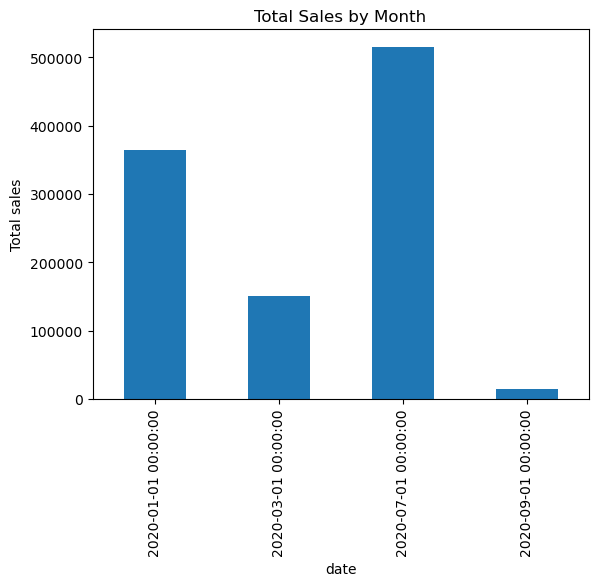

In [18]:
# Bar chart of sales by month
sales_by_month.plot(kind="bar", title="Total Sales by Month")
plt.ylabel("Total sales")
plt.show()

### 3.4 Sales by item type

In [19]:
sales_by_type = df_sales.groupby("item_type")["total_sales"].sum().sort_values(ascending=False)
sales_by_type

item_type
BEER           756818.44
WINE           179148.77
LIQUOR          90539.75
NON-ALCOHOL      9263.04
KEGS             8400.00
Name: total_sales, dtype: float64

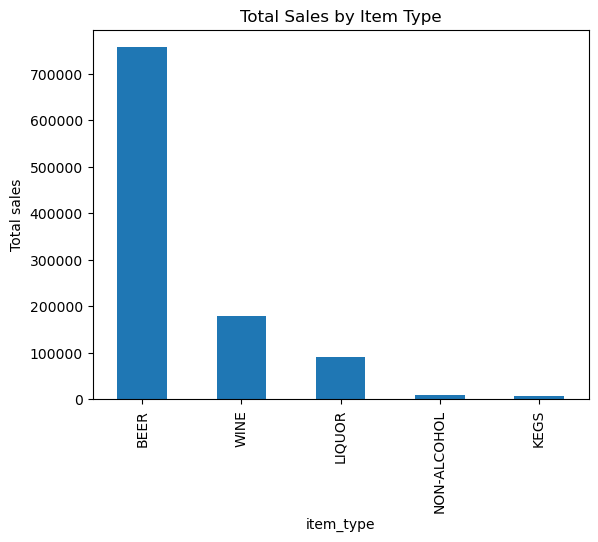

In [20]:
sales_by_type.plot(kind="bar", title="Total Sales by Item Type")
plt.ylabel("Total sales")
plt.show()

### 3.5 Sales by supplier (top 10)

In [21]:
sales_by_supplier = df_sales.groupby("supplier")["total_sales"].sum().sort_values(ascending=False)
sales_by_supplier.head(10)

supplier
CROWN IMPORTS               192434.62
ANHEUSER BUSCH INC          150109.16
MILLER BREWING COMPANY      133017.58
HEINEKEN USA                 97868.70
BOSTON BEER CORPORATION      39069.03
DIAGEO NORTH AMERICA INC     34647.90
E & J GALLO WINERY           30476.24
CONSTELLATION BRANDS         21124.79
FLYING DOG BREWERY LLLP      18477.25
MARK ANTHONY BRANDS INC      18013.69
Name: total_sales, dtype: float64

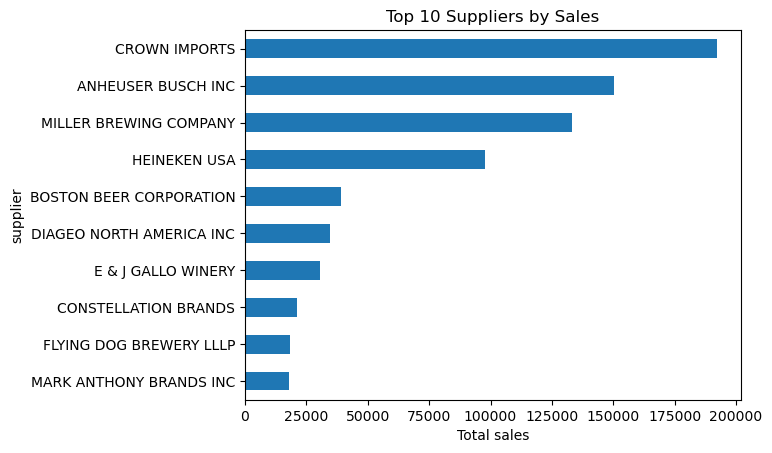

In [22]:
sales_by_supplier.head(10).plot(kind="barh", title="Top 10 Suppliers by Sales")
plt.gca().invert_yaxis()   # biggest on top
plt.xlabel("Total sales")
plt.show()

### 3.6 Sales by product (top 10)

In [23]:
sales_by_product = df_sales.groupby("item_description")["total_sales"].sum().sort_values(ascending=False)
sales_by_product.head(10)

item_description
CORONA EXTRA LOOSE NR - 12OZ            46175.50
HEINEKEN LOOSE NR - 12OZ                24695.88
MODELO ESPECIAL 24 LOOSE NR - 12OZ      20150.00
CORONA EXTRA 2/12 NR - 12OZ             20121.50
HEINEKEN 2/12 NR - 12OZ                 15301.90
MODELO ESPECIAL SUITCASE CANS - 12OZ    12759.84
MILLER LITE 30PK CAN - 12OZ             12693.40
CORONA EXTRA 18PK NR - 12OZ             10961.72
CORONA EXTRA 4/6 NR - 12OZ               9929.04
BUD LIGHT 30PK CAN                       9541.97
Name: total_sales, dtype: float64

## Step 4: Business analysis

### 4.1 Key numbers

In [24]:
total_sales = df_sales["total_sales"].sum()
total_retail = df_sales["retail_sales"].sum()
total_warehouse = df_sales["warehouse_sales"].sum()

print("Total sales:     ", round(total_sales, 2))
print("Retail sales:    ", round(total_retail, 2))
print("Warehouse sales: ", round(total_warehouse, 2))
print("Warehouse share: ", round(total_warehouse / total_sales * 100, 1), "%")

Total sales:      1044170.0
Retail sales:     207795.07
Warehouse sales:  836374.93
Warehouse share:  80.1 %


### 4.2 Best and worst product

In [25]:
print("Best product:  ", sales_by_product.index[0], "->", round(sales_by_product.iloc[0], 2))
print("Worst product: ", sales_by_product.index[-1], "->", round(sales_by_product.iloc[-1], 2))

print()
print("Bottom 5 products:")
sales_by_product.tail(5)

Best product:   CORONA EXTRA LOOSE NR - 12OZ -> 46175.5
Worst product:  LEINENKUGEL SNOW DRIFT VANILLA PRTR 1/2 KG -> -2.0

Bottom 5 products:


item_description
CHOP SHOP CABERNET SAUVIGNON - 20L           -1.0
NEYERS LEFT BANK RED - 750ML                 -1.0
NEW BELGIUM PILSENER 1/2KEG                  -1.0
LAKEFRONT FUEL COFFEE STOUT 4/6 NR - 12OZ    -1.0
LEINENKUGEL SNOW DRIFT VANILLA PRTR 1/2 KG   -2.0
Name: total_sales, dtype: float64

### 4.3 Best and worst month
September has far fewer rows than the other months, so it is probably an **incomplete month**. Be careful calling it the worst month.

In [26]:
print("Best month: ", sales_by_month.idxmax().strftime("%B %Y"), "->", round(sales_by_month.max(), 2))
print("Worst month:", sales_by_month.idxmin().strftime("%B %Y"), "->", round(sales_by_month.min(), 2))

Best month:  July 2020 -> 514974.98
Worst month: September 2020 -> 14065.47


### 4.4 Month-to-month growth (%)
Only 4 months exist in this data (Jan, Mar, Jul, Sep), so this compares each month with the **previous month in the data**, not necessarily the calendar month before.

In [27]:
growth = sales_by_month.pct_change() * 100
growth.round(1)

date
2020-01-01      NaN
2020-03-01    -58.7
2020-07-01    242.1
2020-09-01    -97.3
Name: total_sales, dtype: float64

### 4.5 Supplier performance
We look at: total sales, number of products, and share of all sales.

In [28]:
supplier_table = df_sales.groupby("supplier").agg(
    total_sales=("total_sales", "sum"),
    products=("item_code", "nunique")
)
supplier_table["share_%"] = (supplier_table["total_sales"] / total_sales * 100).round(2)
supplier_table = supplier_table.sort_values("total_sales", ascending=False)
supplier_table.head(10)

,total_sales,products,share_%
supplier,,,
CROWN IMPORTS,192434.62,61,18.43
ANHEUSER BUSCH INC,150109.16,256,14.38
MILLER BREWING COMPANY,133017.58,144,12.74
HEINEKEN USA,97868.70,55,9.37
BOSTON BEER CORPORATION,39069.03,134,3.74
DIAGEO NORTH AMERICA INC,34647.90,310,3.32
E & J GALLO WINERY,30476.24,454,2.92
CONSTELLATION BRANDS,21124.79,277,2.02
FLYING DOG BREWERY LLLP,18477.25,78,1.77


### 4.6 How concentrated are the sales?
How much of the business depends on the top 10 suppliers?

In [29]:
top10_share = supplier_table["share_%"].head(10).sum()
print("Top 10 suppliers make", round(top10_share, 1), "% of all sales")

Top 10 suppliers make 70.4 % of all sales


### 4.7 Best product in each item type

In [30]:
# For each item type, find the product with the highest sales
by_type_product = df_sales.groupby(["item_type", "item_description"])["total_sales"].sum()
by_type_product.groupby("item_type").idxmax().apply(lambda x: x[1])

item_type
BEER            CORONA EXTRA LOOSE NR - 12OZ
KEGS                      STELLA ARTOIS 1/2K
LIQUOR         TITO'S HANDMADE VODKA - 1.75L
NON-ALCOHOL                              ICE
WINE               SUTTER HOME CHARD - 187ML
Name: total_sales, dtype: object

## 6. Chatbot-ready metric objects and interpretation notes

The named tables and scalars above can support deterministic chatbot responses. Keep the cleaned data frame and report tables as the source of truth. For production use, specify whether a question means retail, warehouse, or combined sales; the combined metric here excludes transfers and is not a dollar value.

In [31]:
# Build the business summary metrics used by the chatbot.
business_metrics = {
    "total_sales": float(total_sales),
    "retail_sales": float(total_retail),
    "warehouse_sales": float(total_warehouse),
    "warehouse_share_pct": float((total_warehouse / total_sales) * 100.0),
    "best_product": str(sales_by_product.index[0]),
    "best_product_sales": float(sales_by_product.iloc[0]),
    "worst_product": str(sales_by_product.index[-1]),
    "worst_product_sales": float(sales_by_product.iloc[-1]),
    "best_month": sales_by_month.idxmax(),
    "best_month_sales": float(sales_by_month.max()),
    "worst_month": sales_by_month.idxmin(),
    "worst_month_sales": float(sales_by_month.min()),
    "top_supplier": str(sales_by_supplier.index[0]),
    "top_supplier_sales": float(sales_by_supplier.iloc[0]),
    "top10_supplier_share_pct": float(top10_share),
}

# Prepare the metric objects expected by the chatbot.
analysis_df = df_sales.copy()
yearly_sales = df_sales.groupby("year")["total_sales"].sum().sort_index()
monthly_sales_by_calendar_month = sales_by_month.copy()
supplier_sales = sales_by_supplier.copy()
item_sales = sales_by_product.copy()
item_type_sales = sales_by_type.copy()
monthly_ts = sales_by_month.copy()
seasonal_pattern = growth.copy()

chatbot_metric_tables = {
    "business_metrics": business_metrics,
    "sales_by_year": yearly_sales,
    "sales_by_month": monthly_sales_by_calendar_month,
    "sales_by_supplier": supplier_sales,
    "sales_by_product": item_sales,
    "sales_by_item_type": item_type_sales,
    "monthly_time_series": monthly_ts,
    "seasonal_pattern": seasonal_pattern,
}
print("Available chatbot metric keys:", list(chatbot_metric_tables))
print(f"Rows ready for analysis: {len(analysis_df):,}; products: {len(item_sales):,}; suppliers: {len(supplier_sales):,}")
print(f"Combined total_sales: {total_sales:,.2f} recorded sales quantity")

Available chatbot metric keys: ['business_metrics', 'sales_by_year', 'sales_by_month', 'sales_by_supplier', 'sales_by_product', 'sales_by_item_type', 'monthly_time_series', 'seasonal_pattern']
Rows ready for analysis: 29,916; products: 15,699; suppliers: 287
Combined total_sales: 1,044,170.00 recorded sales quantity
